# Identidade técnica e contexto delegado

25 minutos

[Objetivos e sequência de aprendizagem](../docs/jornada.md).
Execute com o kernel Python de `.venv`.

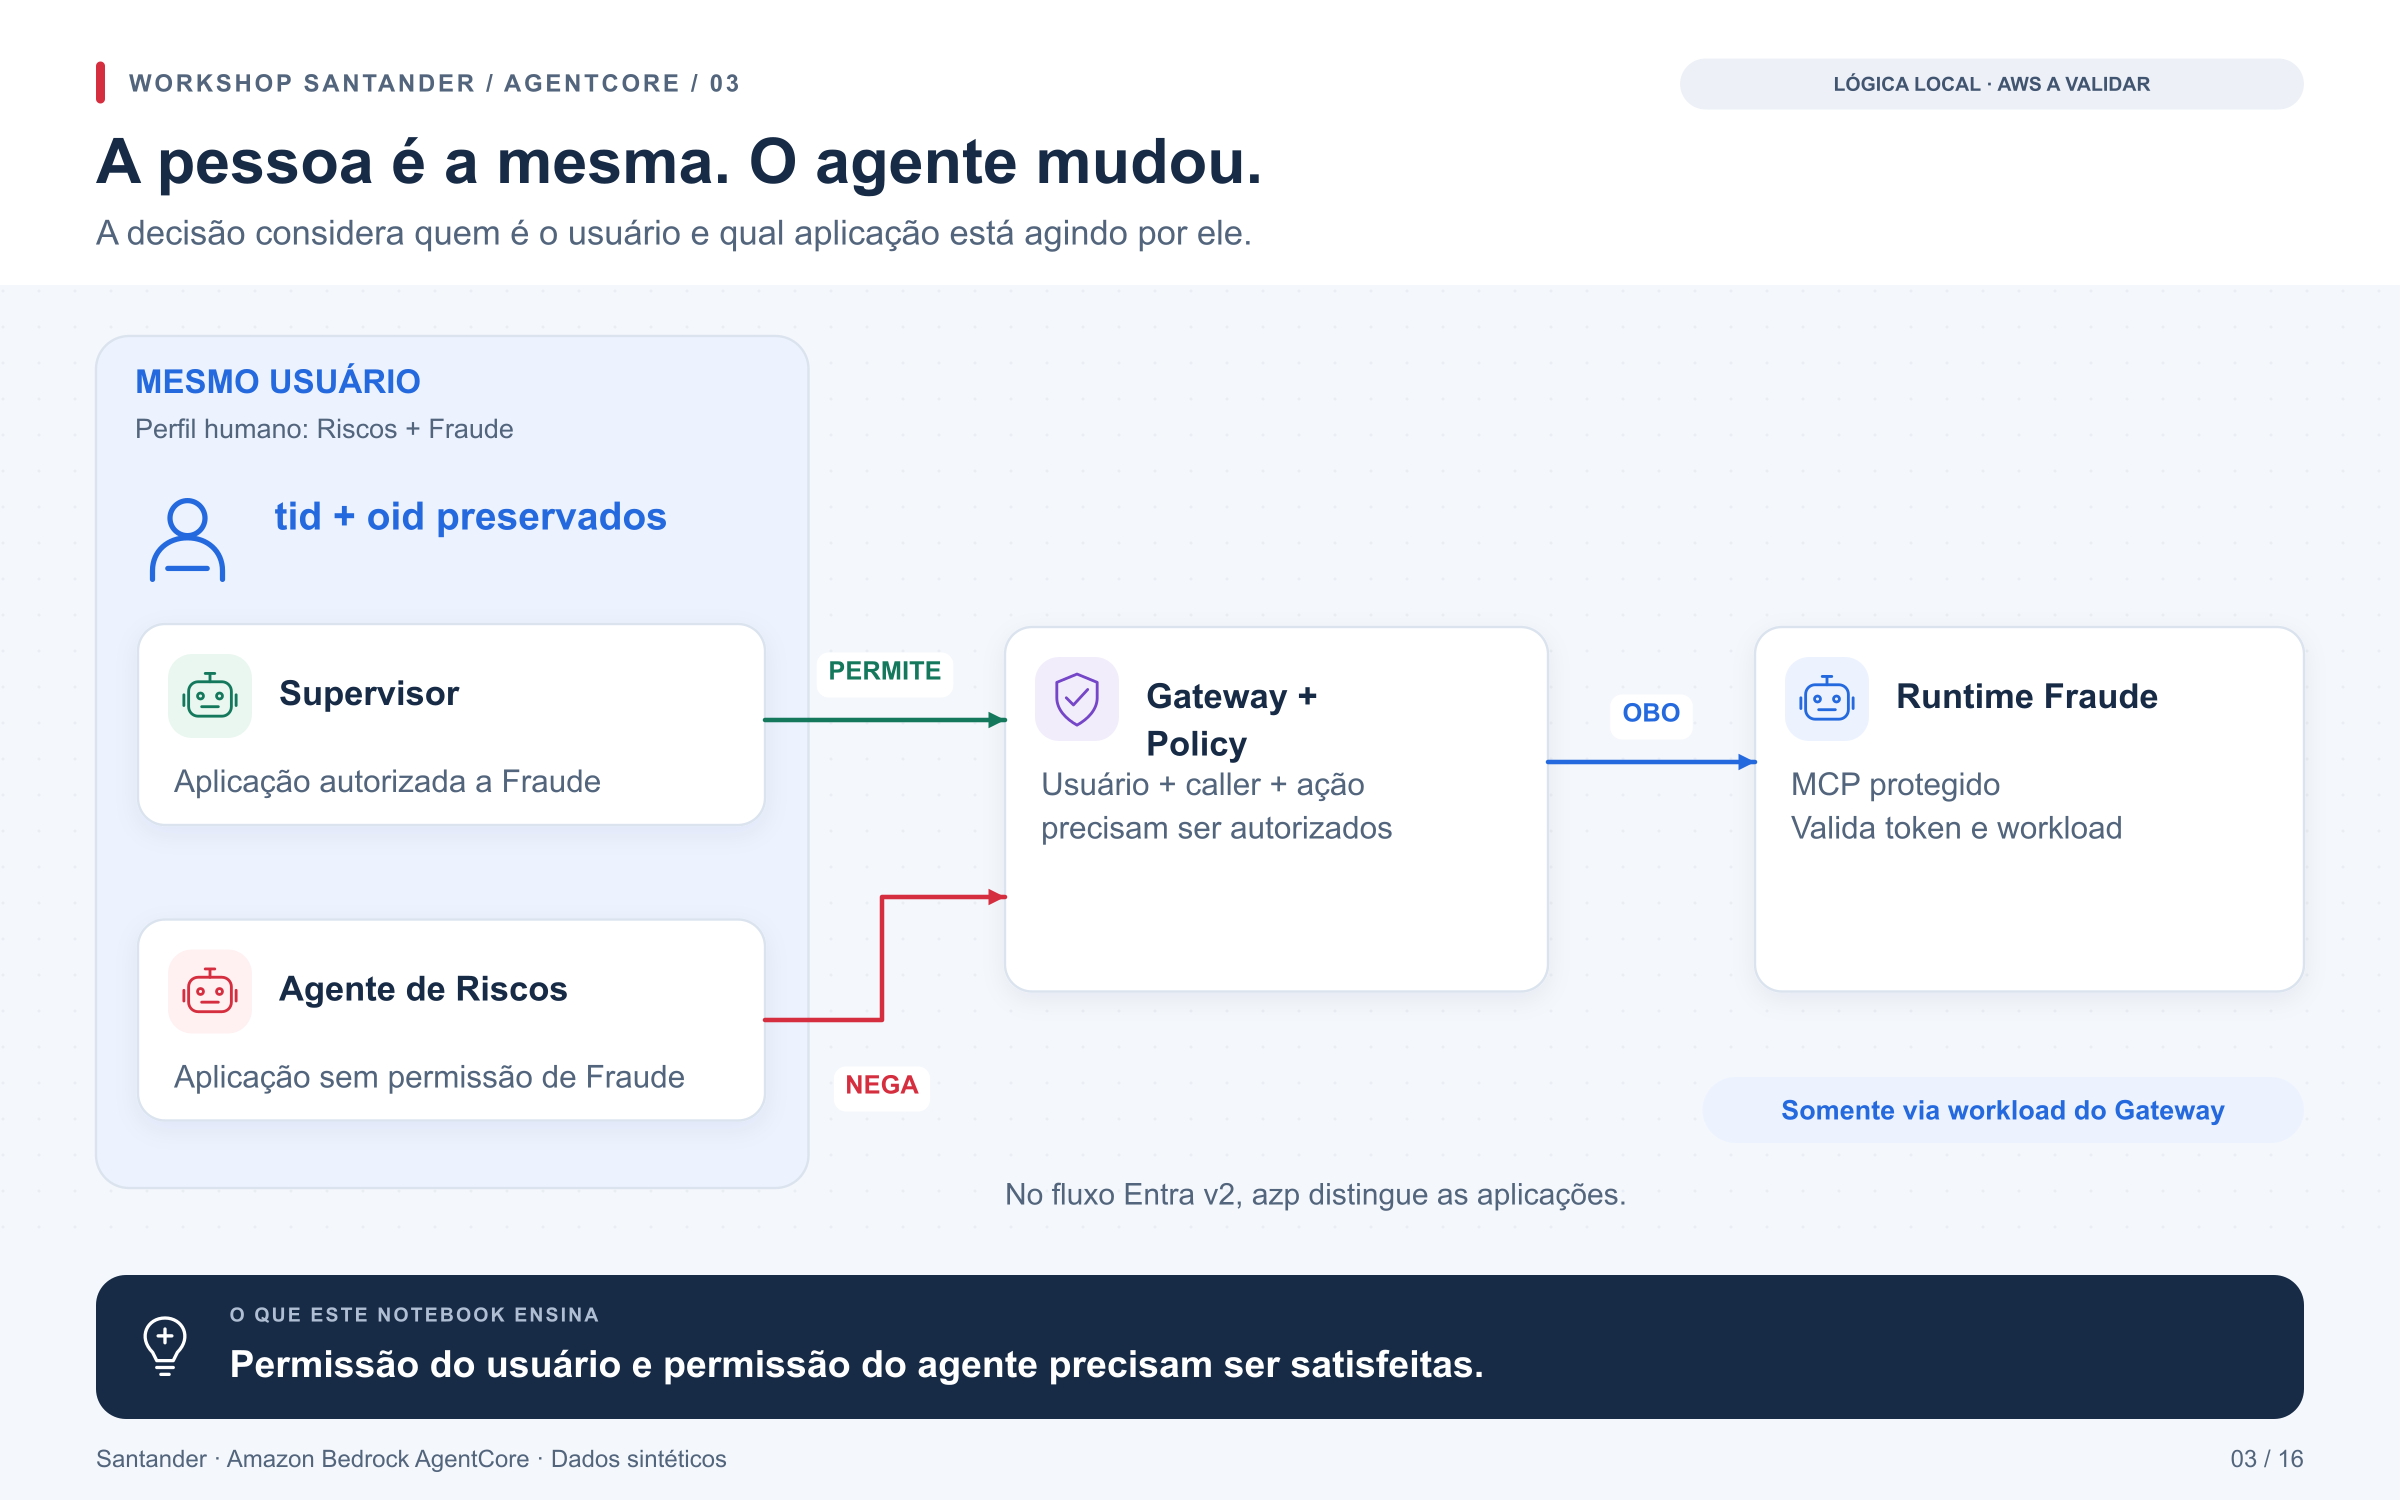

**Objetivo visual:** Mostrar uma mudança de decisão alterando apenas a identidade técnica do chamador.

[Abrir PNG](../docs/diagramas/png/03_identity_agente_mcp.png) · [SVG editável](../docs/diagramas/svg/03_identity_agente_mcp.svg) · [Galeria dos notebooks](../docs/diagramas/index.html)

**Etapa 4 de 17 na jornada.** [Jornada completa](../docs/jornada.md) · [Anterior: Identidade e OBO](02_identity_entra_obo.ipynb) · [Próximo: Autorização Cedar](04_policy_cedar.ipynb)

## Conceitos para acompanhar este laboratório

**Usuário, aplicação e workload são identidades diferentes.** A pessoa pode
usar vários agentes; cada agente apresenta sua própria identidade de aplicação.
Uma workload é a execução de software, como um Gateway ou Runtime.

A política deste exercício combina o usuário (`oid`) e o chamador (`azp`).
Por isso, manter o usuário e trocar `supervisor` por `riscos` pode mudar
a decisão. Os argumentos da ferramenta não escolhem essas claims.

A **restrição de workload** do Runtime é uma fronteira adicional ao JWT:
no IaC, ela limita o chamador ao Gateway declarado. O teste desta célula
verifica apenas Cedar local. A recusa de acesso direto ao Runtime exige
o ensaio AWS com a audiência correta, descrito depois.
Veja [policy.py](../src/santander_demo/policy.py) e
[infra/generate.py](../infra/generate.py).

**Documentação oficial para aprofundar:**

* [Entrada e saída autenticadas no Runtime](https://docs.aws.amazon.com/bedrock-agentcore/latest/devguide/runtime-oauth.html)
* [Claims que identificam usuário e aplicação](https://learn.microsoft.com/pt-br/entra/identity-platform/access-token-claims-reference)
* [Identity: delegação OBO](https://docs.aws.amazon.com/bedrock-agentcore/latest/devguide/on-behalf-of-token-exchange.html)

As explicações estão em português; nomes de APIs, claims e campos permanecem como aparecem no código. As páginas oficiais podem estar em inglês.

O contrato implantado usa OBO nativo no Gateway também para o Runtime Fraude.
O Runtime valida sua própria audiência, a aplicação do Gateway e a restrição de
workload. A pessoa permanece no contexto delegado, enquanto a aplicação
chamadora identifica qual agente atua por ela. Vamos comparar essas
identidades e observar seu efeito na autorização.

### Preparar o ambiente deste notebook

Vamos importar os componentes do workshop, localizar a pasta do projeto e ler
`WORKSHOP_MODE`, cujo padrão é `local`. A instância `lab` reúne o emissor de
tokens de teste, o catálogo em memória, as políticas Cedar e o registro de
evidências que serão usados nas próximas células.

Se o modo for `aws`, também carregaremos `config/local.json` e inicializaremos
o cliente do ambiente configurado. Ao final, a mensagem mostrará o modo ativo;
`LOCAL_SIMULATION` indica que os resultados locais não comprovam a integração
com AWS ou Entra. Reexecutar esta célula reinicia o estado local do laboratório.

In [ ]:
import os
from pathlib import Path
from santander_demo.local import Workshop
from santander_demo.contracts import CLIENTE, DemoError

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
MODE = os.environ.get("WORKSHOP_MODE", "local")
assert MODE in {"local", "aws"}, "WORKSHOP_MODE deve ser local ou aws"
lab = Workshop()
cloud = None
if MODE == "aws":
    from santander_demo.config import Environment
    from santander_demo.cloud import CloudWorkshop
    config = Environment.load(ROOT / "config/local.json")
    cloud = CloudWorkshop(config)
print("LOCAL_SIMULATION — nenhuma prova de AWS/Entra" if MODE == "local" else "AWS — integração real")

### Comparar dois agentes atuando pelo mesmo usuário

Vamos emitir dois tokens locais para o usuário `ambos`, mudando
apenas a aplicação chamadora: `supervisor` ou `riscos`. Primeiro,
confirmaremos que o supervisor consegue consultar Fraude. Depois,
repetiremos a consulta como agente de Riscos e exigiremos `POLICY_DENY`.

O contador de invocações será medido antes e depois da tentativa
negada para verificar que ela não chegou ao backend. A saída esperada
é `same_user_different_caller: PASS`. Esta célula usa o laboratório
local mesmo quando `WORKSHOP_MODE` está definido como `aws`.

In [ ]:
permitted = lab.idp.token("ambos", "supervisor")
restricted = lab.idp.token("ambos", "riscos")
assert lab.call(permitted, "fraude___consultar_fraude",
                {"cliente_id": CLIENTE, "max_registros": 1})["synthetic"]
before = lab.evidence.backend_invocations
try:
    lab.call(restricted, "fraude___consultar_fraude",
             {"cliente_id": CLIENTE, "max_registros": 1})
    raise AssertionError("Chamador indevido autorizado")
except DemoError as exc:
    assert exc.code == "POLICY_DENY"
assert lab.evidence.backend_invocations == before
print({"mode": "LOCAL_SIMULATION", "same_user_different_caller": "PASS"})

**Prova AWS:** com o mesmo usuário, obtenha tokens por dois clientes Entra
distintos (supervisor e riscos). Repita a chamada de Fraude; valide a negativa no
Gateway e a ausência de execução no backend. Não altere `azp` manualmente:
isso invalida a assinatura.

Verifique também que chamar o Runtime Fraude diretamente é recusado. O template
configura `AllowedWorkloadConfiguration` com o ARN do Gateway. A disponibilidade
desse vínculo para o caminho MCP e entre as contas escolhidas é um gate do ensaio.

## Limpeza — recursos do laboratório

Os notebooks **00–06, 08, 10 e 13 compartilham o ambiente**. Remova os stacks somente
ao encerrar toda a trilha, depois de salvar as evidências.

1. Atualize `origin` com `EnableRuntime=false` pelo `scripts/deploy.py`.
2. Remova `registry`; preserve o output de `policy-draft`, se utilizado,
   antes de remover seu stack. O histórico de geração usa `Retain`.
3. Atualize `hub` com `EnableFraud=false` pelo `scripts/deploy.py`.
4. Remova `fraud-runtime`, depois `hub` e, por último, `origin`.
5. Remova os stacks `bootstrap` somente após revisar os artefatos retidos.

Para cada remoção, use o template correspondente e o **nome real do stack**
implantado. Os nomes de template acima não determinam os nomes dos stacks.
Buckets usam `Retain`; aplicações e segredos Entra seguem o Terraform que os
gerencia. O notebook 13 não é proprietário do workspace, warehouse ou grants
Databricks. Consulte o [runbook da trilha](../docs/deploy.md#9-limpeza).

**Na próxima célula**, `CLEANUP_TARGET=None` manterá a remoção desativada e
imprimirá `cloud_cleanup: NOT_RUN`. Para revisar um stack real, preencha o
alvo indicado no comentário e mantenha `CLEANUP_EXECUTE=False`. O script
`scripts/cleanup.py` consultará STS e CloudFormation, exigirá correspondência
exata entre template implantado e fonte local e mostrará o ARN, as retenções
declaradas e eventuais bloqueios. Essa preparação faz somente leituras.

Após revisar o plano e a ordem acima, copie seu ARN para
`CLEANUP_CONFIRM_STACK_ID` e habilite `CLEANUP_EXECUTE` para remover **esse
stack** pelo wrapper IaC. O script aguarda a exclusão pelo CloudFormation,
respeita `Retain` e não desativa proteções. Falhas devem ser resolvidas no
IaC. A execução padrão deste notebook não remove recursos em nuvem.

In [ ]:
import subprocess as _cleanup_subprocess
import sys as _cleanup_sys

# Preencha somente para um stack do laboratório, após encerrar a trilha:
# {"template": "TEMPLATE", "stack": "NOME_REAL", "profile": "PERFIL",
#   "account": "ID_DA_CONTA", "region": "REGIAO"}
CLEANUP_TARGET = None
CLEANUP_EXECUTE = False
CLEANUP_CONFIRM_STACK_ID = ""

if CLEANUP_TARGET is None:
    print({"cloud_cleanup": "NOT_RUN", "reason": "Nenhum stack selecionado"})
else:
    assert set(CLEANUP_TARGET) == {"template", "stack", "profile", "account", "region"}
    _cleanup_command = [
        _cleanup_sys.executable, str(ROOT / "scripts/cleanup.py"),
        "--scenario", "workshop",
    ]
    for _cleanup_key, _cleanup_value in CLEANUP_TARGET.items():
        _cleanup_command.extend(["--" + _cleanup_key, _cleanup_value])
    if CLEANUP_EXECUTE:
        assert CLEANUP_CONFIRM_STACK_ID, "Revise o plano e informe o ARN exato do stack"
        _cleanup_command.extend(["--execute", "--confirm-stack-id", CLEANUP_CONFIRM_STACK_ID])
    _cleanup_subprocess.run(_cleanup_command, cwd=ROOT, check=True)

### Limpeza — estado local do notebook

Vamos remover as variáveis de dados, tokens, clientes e configuração criadas
por este exercício. As sessões MCP abertas com `async with` já foram encerradas
ao sair de seus blocos; o cliente de controle de `cloud`, quando presente,
também será fechado. A célula verificará que os nomes listados deixaram
de existir e exibirá `cleanup_local: PASS`; ela pode ser repetida.

Os notebooks, diagramas, templates e arquivos de evidências serão preservados.
Esta limpeza remove referências do namespace; não revoga tokens nem apaga
outputs ou todas as cópias que possam existir na memória do processo.
Após salvar as evidências, limpe as saídas e encerre o kernel para terminar
a sessão. Para repetir o laboratório, recomece pela preparação do ambiente.

In [ ]:
import json as _cleanup_json

if globals().get("cloud") is not None:
    cloud.control.close()
_cleanup_names = ['CLEANUP_CONFIRM_STACK_ID', 'CLEANUP_EXECUTE', 'CLEANUP_TARGET', 'MODE',
 '_cleanup_command', '_cleanup_key', '_cleanup_subprocess', '_cleanup_sys',
 '_cleanup_value', 'before', 'cloud', 'config', 'identity', 'lab', 'permitted',
 'restricted', 'token']
_cleanup_removed = [name for name in _cleanup_names if name in globals()]
for _cleanup_name in _cleanup_names:
    globals().pop(_cleanup_name, None)
assert not any(name in globals() for name in _cleanup_names)
print(_cleanup_json.dumps({
    "cleanup_local": "PASS",
    "removed_variables": len(_cleanup_removed),
    "files": "PRESERVED",
}, ensure_ascii=False))
del _cleanup_name, _cleanup_names, _cleanup_removed, _cleanup_json